# 01. LM Studio – konfiguracja, API i znaczenie parametrów generowania

Notebook pokazuje **podstawową funkcjonalność projektu zrealizowaną gotowym narzędziem** (LM Studio + llama.cpp):
wywołania lokalnego modelu przez API zgodne z OpenAI i wpływ parametrów generowania na wynik.
Kroki instalacji i ładowania modeli: `docs/01_konfiguracja_lm_studio.md`.

| Model (LM Studio) | Rola |
|---|---|
| `google/gemma-4-12b-qat` (Q4_0, 12B, + mmproj) | LLM – generowanie, klasyfikacja, obraz |
| `text-embedding-bge-m3` (Q8_0) | embeddingi do wyszukiwania semantycznego |

**Wymaganie:** uruchomiony serwer LM Studio (`lms server start`) z załadowanymi modelami.

In [1]:
import time, statistics
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from openai import OpenAI

BASE_URL, LLM, EMB = "http://localhost:1234/v1", "google/gemma-4-12b-qat", "text-embedding-bge-m3"
client = OpenAI(base_url=BASE_URL, api_key="lm-studio")   # klucz nie jest sprawdzany przez LM Studio
print([m.id for m in client.models.list().data])

['google/gemma-4-12b-qat', 'text-embedding-bge-m3', 'text-embedding-nomic-embed-text-v1.5']


## 1. Pierwsze zapytanie i anatomia odpowiedzi
Parametry spoza specyfikacji OpenAI (`top_k`, `repeat_penalty`, `reasoning_effort`) przekazujemy w `extra_body`.

In [2]:
def ask(prompt, temperature=0.2, top_p=0.9, top_k=40, max_tokens=300, seed=None,
        repeat_penalty=1.1, reasoning="none", system=None):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    t0 = time.perf_counter()
    r = client.chat.completions.create(
        model=LLM, messages=msgs, temperature=temperature, top_p=top_p, max_tokens=max_tokens, seed=seed,
        extra_body={"top_k": top_k, "repeat_penalty": repeat_penalty, "reasoning_effort": reasoning})
    return {"text": r.choices[0].message.content or "", "finish": r.choices[0].finish_reason,
            "tokens": r.usage.completion_tokens, "prompt_tokens": r.usage.prompt_tokens,
            "reasoning_tokens": getattr(r.usage.completion_tokens_details, "reasoning_tokens", None),
            "time_s": round(time.perf_counter() - t0, 2)}

res = ask("Wyjaśnij w dwóch zdaniach, czym jest Retrieval-Augmented Generation.")
print(res["text"]); {k: v for k, v in res.items() if k != "text"}

Retrieval-Augmented Generation (RAG) to technika wykorzystywana w modelach językowych, która polega na dostarczaniu im dodatkowych, zewnętrznych danych w celu uzupełnienia ich wiedzy przed wygenerowaniem odpowiedzi. Dzięki temu model może udzielać bardziej precyzyjnych i aktualnych informacji, opierając się na konkretnych źródłach zamiast wyłącznie na danych, na których został wytrenowany.


{'finish': 'stop',
 'tokens': 91,
 'prompt_tokens': 30,
 'reasoning_tokens': 0,
 'time_s': 1.42}

## 2. Temperature – kreatywność vs powtarzalność
Ten sam prompt generujemy 4 razy (bez stałego seeda) dla różnych temperatur i liczymy, ile odpowiedzi jest
różnych oraz jak bogate jest słownictwo (type-token ratio, jak w Lab 1–2).

In [3]:
PROMPT = "Wymyśl jedno krótkie hasło reklamowe (maks. 10 słów) dla sklepu z elektroniką o nazwie Zorza."
rows = []
for T in [0.0, 0.4, 0.8, 1.2, 1.6]:
    outs = [ask(PROMPT, temperature=T, top_p=1.0, top_k=100, max_tokens=60)["text"].strip() for _ in range(4)]
    words = " ".join(outs).lower().split()
    rows.append({"temperature": T, "unikalne_odpowiedzi": len(set(outs)), "TTR": round(len(set(words)) / len(words), 3),
                 "przykład_1": outs[0], "przykład_2": outs[1]})
df_t = pd.DataFrame(rows); df_t

,temperature,unikalne_odpowiedzi,TTR,przykład_1,przykład_2
0,0.0,1,0.250,**Zorza – Twój świat technologii w zasięgu ręk...,**Zorza – Twój świat technologii w zasięgu ręk...
1,0.4,3,0.484,**Zorza – Twój świat technologii w zasięgu ręk...,Oto propozycja:\n\n**Zorza – Twój jasny wybór ...
2,0.8,4,0.472,Oto propozycja:\n\n**Zorza – Twoja nowa techno...,Oto propozycja:\n\n**Zorza – Twój świat techno...
3,1.2,4,0.559,**Zorza – Twój świat technologii w zasięgu ręk...,Oto propozycja:\n\n**Zorza – Twój świat techno...
4,1.6,3,0.545,Oto propozycja:\n\n**Zorza – rozświetl swój św...,Oto propozycja:\n\n**Zorza – rozświetl swoją t...


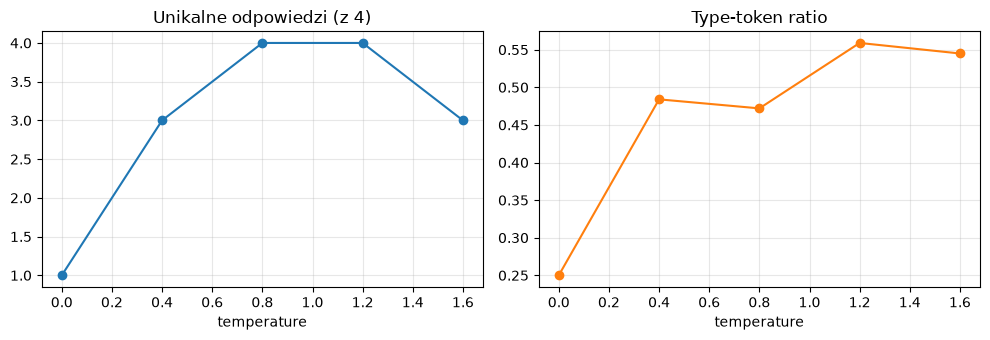

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(df_t.temperature, df_t.unikalne_odpowiedzi, "o-"); ax[0].set_title("Unikalne odpowiedzi (z 4)")
ax[1].plot(df_t.temperature, df_t.TTR, "o-", color="tab:orange"); ax[1].set_title("Type-token ratio")
for a in ax: a.set_xlabel("temperature"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. Seed – powtarzalność przy losowaniu
Przy temperaturze 1.0 odpowiedzi są losowe, ale **ten sam seed** daje ten sam wynik – ważne w ewaluacji.

In [5]:
a = ask(PROMPT, temperature=1.0, seed=123)["text"]; b = ask(PROMPT, temperature=1.0, seed=123)["text"]
c = ask(PROMPT, temperature=1.0, seed=999)["text"]
print("seed 123 (1):", a); print("seed 123 (2):", b); print("seed 999   :", c)
print("\nseed 123 identyczne:", a == b, "| seed 999 inny:", a != c)

seed 123 (1): Oto propozycja:

**Zorza – Twój nowy wymiar technologii.**
seed 123 (2): Oto propozycja:

**Zorza – Twój nowy wymiar technologii.**
seed 999   : **Zorza – Twój świat nowoczesnej technologii.**

seed 123 identyczne: True | seed 999 inny: True


## 4. top_k i top_p – zawężanie puli losowanych tokenów
`top_k=1` oznacza zawsze najbardziej prawdopodobny token (dekodowanie zachłanne) – nawet przy wysokiej temperaturze.

In [6]:
rows = []
for name, kw in {"T=1.2, top_k=1": dict(top_k=1, top_p=1.0), "T=1.2, top_k=5": dict(top_k=5, top_p=1.0),
                 "T=1.2, top_p=0.3": dict(top_k=100, top_p=0.3), "T=1.2, top_p=1.0": dict(top_k=100, top_p=1.0)}.items():
    outs = [ask(PROMPT, temperature=1.2, max_tokens=60, **kw)["text"].strip() for _ in range(4)]
    rows.append({"ustawienie": name, "unikalne_z_4": len(set(outs)), "przykład": outs[0]})
pd.DataFrame(rows)

,ustawienie,unikalne_z_4,przykład
0,"T=1.2, top_k=1",1,**Zorza – Twój świat technologii w zasięgu ręk...
1,"T=1.2, top_k=5",4,**Zorza – Twój nowy wymiar technologii.**
2,"T=1.2, top_p=0.3",1,**Zorza – Twój świat technologii w zasięgu ręk...
3,"T=1.2, top_p=1.0",3,Oto propozycja:\n\n**Zorza – Twój nowy wymiar ...


## 5. max_tokens – ucinanie odpowiedzi
Gdy limit zostanie osiągnięty, `finish_reason = "length"`, a odpowiedź jest niekompletna.

In [7]:
for mt in [20, 80, 2000]:
    r = ask("Opisz krok po kroku, jak zwrócić towar kupiony w sklepie internetowym.", max_tokens=mt)
    print(f"max_tokens={mt:3d} -> finish={r['finish']:6s} tokeny={r['tokens']:3d} | {r['text'][:110]!r}")

max_tokens= 20 -> finish=length tokeny= 20 | 'Proces zwrotu towaru kupionego online jest ściśle uregulowany przez prawo ('


max_tokens= 80 -> finish=length tokeny= 80 | 'Proces zwrotu towaru kupionego online jest ściśle uregulowany prawem (w Unii Europejskiej obowiązuje prawo do '


max_tokens=2000 -> finish=stop   tokeny=1073 | 'Proces zwrotu towaru kupionego online jest ściśle uregulowany przez prawo (w Unii Europejskiej obowiązuje praw'


## 6. repeat_penalty – kara za powtórzenia

In [8]:
for rp in [1.0, 1.3]:
    r = ask("Wypisz 15 zalet zakupów w sklepie internetowym, każda w jednej linii.", temperature=0.3,
            repeat_penalty=rp, max_tokens=300)
    lines = [l for l in r["text"].splitlines() if l.strip()]
    first_words = [l.split()[1].lower() if len(l.split()) > 1 else "" for l in lines]
    print(f"repeat_penalty={rp}: linii={len(lines)}, unikalnych pierwszych słów={len(set(first_words))}")

repeat_penalty=1.0: linii=15, unikalnych pierwszych słów=9


repeat_penalty=1.3: linii=14, unikalnych pierwszych słów=9


## 7. reasoning_effort – model „rozumujący”
Gemma 4 domyślnie generuje ukryty tok rozumowania (`reasoning_content`), który **wlicza się do `max_tokens`**
i wydłuża czas. W pipeline'ie FAQ rozumowanie jest wyłączone (`none`).

In [9]:
Q = 'Sklep: darmowa dostawa od 299 zł, kurier 14,99 zł, pobranie +5 zł. Ile zapłacę za kuriera z pobraniem przy koszyku 250 zł? Podaj samą kwotę.'
rows = []
for eff in ["none", "low", "high"]:
    r = ask(Q, temperature=0, max_tokens=2000, reasoning=eff)
    rows.append({"reasoning_effort": eff, "tokeny_rozumowania": r["reasoning_tokens"], "tokeny_razem": r["tokens"],
                 "czas_s": r["time_s"], "odpowiedź": r["text"].strip()[:80]})
r_small = ask("Ile kosztuje dostawa? Odpowiedz JSON-em {\"category\": ...}", temperature=0, max_tokens=30, reasoning="high")
print("rozumowanie włączone + max_tokens=30 ->", repr(r_small["text"]), r_small["finish"])
pd.DataFrame(rows)

rozumowanie włączone + max_tokens=30 -> '' length


,reasoning_effort,tokeny_rozumowania,tokeny_razem,czas_s,odpowiedź
0,none,0,7,0.14,"19,99 zł"
1,low,191,202,2.28,"19,99 zł"
2,high,191,202,2.27,"19,99 zł"


## 8. Streaming – odpowiedź token po tokenie (tak działa czat w aplikacji)

In [10]:
stream = client.chat.completions.create(model=LLM, stream=True, max_tokens=60, temperature=0.2,
    messages=[{"role": "user", "content": "Podaj 3 krótkie porady dotyczące bezpiecznych zakupów online."}],
    extra_body={"reasoning_effort": "none"})
t0, first = time.perf_counter(), None
for chunk in stream:
    if chunk.choices and chunk.choices[0].delta.content:
        first = first or time.perf_counter() - t0
        print(chunk.choices[0].delta.content, end="", flush=True)
print(f"\n\nczas do pierwszego tokenu: {first:.2f}s")

O

to

3

 krótk

ie

 por

... (48 outputs left out)

 się

,

 że



czas do pierwszego tokenu: 0.05s


## 9. Embeddingi (bge-m3) – podstawa wyszukiwania semantycznego
Zdania o tym samym znaczeniu mają wysokie podobieństwo cosinusowe mimo innych słów.

wymiar wektora: 1024


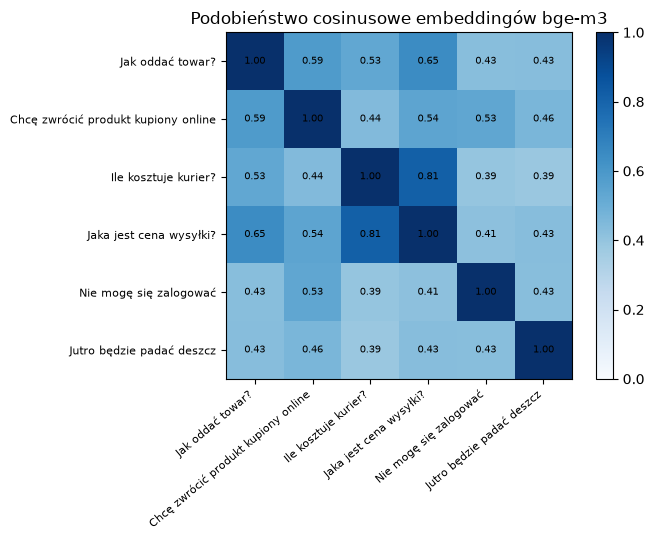

In [11]:
S = ["Jak oddać towar?", "Chcę zwrócić produkt kupiony online", "Ile kosztuje kurier?",
     "Jaka jest cena wysyłki?", "Nie mogę się zalogować", "Jutro będzie padać deszcz"]
E = np.array([d.embedding for d in client.embeddings.create(model=EMB, input=S).data])
E /= np.linalg.norm(E, axis=1, keepdims=True); sim = E @ E.T
print("wymiar wektora:", E.shape[1])
fig, ax = plt.subplots(figsize=(7, 5.5)); im = ax.imshow(sim, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(S)), S, rotation=40, ha="right", fontsize=8); ax.set_yticks(range(len(S)), S, fontsize=8)
for i in range(len(S)):
    for j in range(len(S)): ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Podobieństwo cosinusowe embeddingów bge-m3"); plt.tight_layout(); plt.show()

## 10. Wielomodalność – obraz na wejściu (próg 3.5)
Dzięki projektorowi `mmproj` Gemma przyjmuje obraz (zakodowany base64 w wiadomości).

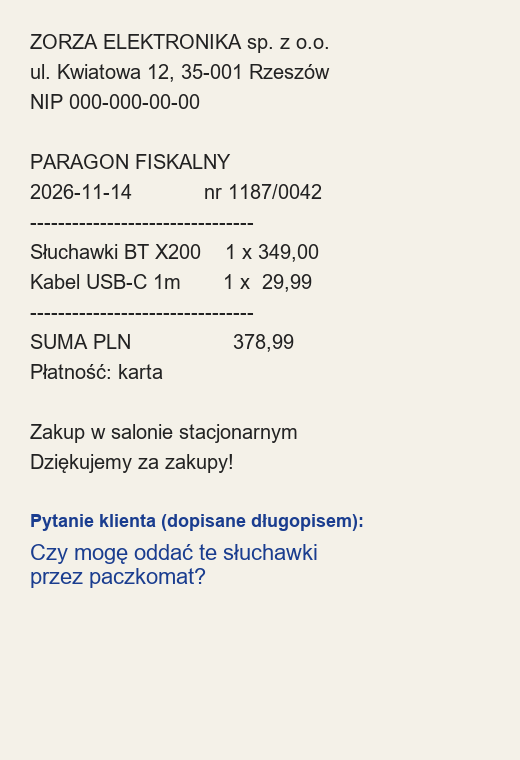

Na podstawie obrazu można odczytać następujące informacje:

*   **Gdzie kupiono produkty:** W sklepie ZORZA ELEKTRONIKA sp. z o.o. przy ul. Kwiatowej 12 w Rzeszowie (zakup odbył się w salonie stacjonarnym).
*   **Co kupiono:** Słuchawki BT X200 oraz kabel USB-C 1m.
*   **Jakie pytanie ma klient:** „Czy mogę oddać te słuchawki przez paczkomat?”


In [12]:
import base64
from IPython.display import Image, display
img_path = "../data/examples/paragon_pytanie.png"; display(Image(img_path, width=260))
b64 = base64.b64encode(open(img_path, "rb").read()).decode()
r = client.chat.completions.create(model=LLM, max_tokens=300, temperature=0.1, extra_body={"reasoning_effort": "none"},
    messages=[{"role": "user", "content": [
        {"type": "text", "text": "Odczytaj z obrazu: gdzie kupiono produkty, co kupiono i jakie pytanie ma klient?"},
        {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64}"}}]}])
print(r.choices[0].message.content)

## Wnioski
* **temperature** steruje różnorodnością: przy T=0 wszystkie próby dają tę samą odpowiedź, od T≈0.8 każda jest inna,
  a bogactwo słownictwa (TTR) rośnie. W odpowiedziach RAG używamy T=0.2 (fakty, powtarzalność),
  w generowaniu danych treningowych T=1.0 (różnorodność).
* **seed** zapewnia powtarzalność nawet przy losowaniu – w ewaluacji ustawiamy seed=0.
* **top_k / top_p** ograniczają pulę losowanych tokenów: `top_k=1` lub małe `top_p` dają wynik praktycznie
  deterministyczny nawet przy wysokiej temperaturze.
* **max_tokens** ucina odpowiedź (`finish_reason="length"`) – limit trzeba dobrać do zadania.
* **reasoning_effort** – model rozumujący zużywa setki ukrytych tokenów i kilka razy więcej czasu; przy małym
  `max_tokens` zwraca pustą treść. Poziomy `low` i `high` dały w LM Studio identyczny wynik (191 tokenów
  rozumowania), a odpowiedź była taka sama jak bez rozumowania. W pipeline'ie FAQ rozumowanie jest wyłączone.
* **repeat_penalty** w tym eksperymencie nie zmienił wyraźnie wyniku (liczba różnych początków linii ta sama) –
  przy niskiej temperaturze i krótkiej liście model sam unika powtórzeń; kara ma znaczenie przy długich tekstach.
* **embeddingi bge-m3** dobrze oddają znaczenie po polsku (parafrazy mają wyraźnie wyższe podobieństwo niż zdania
  o innym temacie) – to podstawa wyszukiwania semantycznego w etapie 2.
* **obraz** – model z projektorem `mmproj` poprawnie odczytuje paragon i pytanie klienta (wielomodalność, próg 3.5).